# Experiment Training Notebook

Loads the `.npz` and warm-state files written by [`combined_data_split.ipynb`](combined_data_split.ipynb) (depth and no-depth variants) and runs a sweep over `(dataset, feature_subset, architecture, loss, lr_strategy)`, split across **4 VMs** (`MY_SHARD` picks this VM's share). Each run adds one row to `experiment_log__shard{MY_SHARD}.csv`. The **Results viewer** at the bottom merges every `experiment_log__shard*.csv` it finds.

**Sweep design**: the loss for each architecture comes from the loss sweep at the end of `combined_data_split.ipynb`. This notebook only varies the feature subset and the lr strategy (fixed or lr_find) for those arch-loss pairs.


In [2]:
import pandas as pd
import os
import socket
import subprocess
import uuid
import gc as _gc
import sys as _sys
from pathlib import Path
import numpy as np
import time
from datetime import datetime
import json as _json

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from fastai.learner import *
from fastai.metrics import accuracy
from fastai.callback.tracker import EarlyStoppingCallback, SaveModelCallback
from fastai.losses import CrossEntropyLossFlat, FocalLossFlat, LabelSmoothingCrossEntropyFlat
from IPython.display import clear_output, display

from geoxts.benchmark_data import *
import geoxts.benchmark_data as _bd
from geoxts.benchmark_data import Well_grlog_cleaning as _orig_Well_grlog_cleaning
from geoxts.benchmark_models import *
from tsai.all import TSDatasets, TSDataLoaders, TSStandardize, Categorize, combine_split_data
from tsai.all import FCN, LSTM, XCM, LSTM_FCN

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# logged with every run so results from different VMs can be told apart
MACHINE = socket.gethostname()
try:
    GIT_SHA = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL
    ).decode().strip()
except Exception:
    GIT_SHA = "unknown"
print(f"Machine: {MACHINE} | git: {GIT_SHA}")


Machine: instance-20260325-155643-dsba-crp-clf | git: unknown


In [3]:
# fixed seed and deterministic CUDA so runs are reproducible
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'   # needed for deterministic mode

random_seed(0, use_cuda=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# raises an error on any non-deterministic op
torch.use_deterministic_algorithms(True)
print("Fully deterministic mode enabled")


Fully deterministic mode enabled


## Cold load: per-dataset loaders (depth vs no-depth)

Each dataset variant produced by `combined_data_split.ipynb` lives in its own subdirectory:

| `dataset_tag` | Directory | Files |
|---|---|---|
| `"nodepth"` | `no_depth/` | `train.npz`, `val.npz`, `test.npz`, `warm_df_test_g.parquet`, `warm_tops.parquet`, `warm_state.json` |
| `"depth"` | `depth/` | `train_depth.npz`, `val_depth.npz`, `test_depth.npz`, `warm_df_test_g_depth.parquet`, `warm_tops_depth.parquet`, `warm_state_depth.json` |

`load_dataset(tag)` returns everything the loop needs. For datasets with `USE_DEPTH=True` it also patches `Well_grlog_cleaning` so Depth is scaled at prediction time the same way as in training.

In [4]:
# same folders and file suffixes as combined_data_split.ipynb writes
DATASET_PATHS = {
    "nodepth": {"dir": "no_depth", "suffix": ""},
    "depth":   {"dir": "depth",    "suffix": "_depth"},
}


def _file(dataset_tag, basename_template):
    """e.g. _file("depth", "train{suffix}.npz") -> "depth/train_depth.npz" """
    info = DATASET_PATHS[dataset_tag]
    return str(Path(info["dir"]) / basename_template.format(suffix=info["suffix"]))


def _install_depth_patch(depth_bounds):
    """Patch Well_grlog_cleaning to min-max scale Depth, as in combined_data_split.ipynb.

    get_markers calls Well_grlog_cleaning at prediction time, so without the patch
    the model would get unscaled depth.
    """
    def _wgc_with_depth_norm(well_name, df_log, input_variable):
        df_wgr = _orig_Well_grlog_cleaning(well_name, df_log, input_variable)
        if 'Depth' in df_wgr.columns:
            lo, hi = depth_bounds
            df_wgr['Depth'] = ((df_wgr['Depth'] - lo) / (hi - lo)).clip(0, 1)
        return df_wgr
    _wgc_with_depth_norm._depth_patched = True
    _bd.Well_grlog_cleaning = _wgc_with_depth_norm
    globals()['Well_grlog_cleaning'] = _wgc_with_depth_norm


def _uninstall_depth_patch():
    """Restore the original Well_grlog_cleaning."""
    _bd.Well_grlog_cleaning = _orig_Well_grlog_cleaning
    globals()['Well_grlog_cleaning'] = _orig_Well_grlog_cleaning


def load_dataset(dataset_tag):
    """Load the arrays, test logs, tops and warm state for one dataset variant into a dict."""
    if dataset_tag not in DATASET_PATHS:
        raise KeyError(f"Unknown dataset_tag={dataset_tag!r}. Known: {list(DATASET_PATHS)}")

    train_data = np.load(_file(dataset_tag, "train{suffix}.npz"))
    val_data   = np.load(_file(dataset_tag, "val{suffix}.npz"))
    test_data  = np.load(_file(dataset_tag, "test{suffix}.npz"))
    df_test_g  = pd.read_parquet(_file(dataset_tag, "warm_df_test_g{suffix}.parquet"))
    tops_df    = pd.read_parquet(_file(dataset_tag, "warm_tops{suffix}.parquet"))
    with open(_file(dataset_tag, "warm_state{suffix}.json")) as f:
        ws = _json.load(f)

    out = {
        "X_train": train_data['X'],
        "y_train": train_data['y'].astype(np.int64),
        "X_val":   val_data['X'],
        "y_val":   val_data['y'].astype(np.int64),
        "X_test":  test_data['X'],
        "y_test":  test_data['y'].astype(np.int64),
        "df_test_g": df_test_g,
        "tops": tops_df,
        "test_wells": set(ws["test_wells"]),
        "well2id": {str(k): v for k, v in ws["well2id"].items()},
        "MARKERS": ws["MARKERS"],
        "FEATURES_GEOX": ws["FEATURES_GEOX"],
        "WELL_COL": ws["WELL_COL"],
        "USE_DEPTH": ws.get("USE_DEPTH", False),
        "DEPTH_BOUNDS": ws.get("DEPTH_BOUNDS"),
        "dataset_tag": dataset_tag,
    }

    if out["USE_DEPTH"] and 'Depth' in out["FEATURES_GEOX"]:
        _install_depth_patch(out["DEPTH_BOUNDS"])
    else:
        _uninstall_depth_patch()

    return out


def dataset_available(dataset_tag):
    """True if all files for dataset_tag are on disk."""
    if dataset_tag not in DATASET_PATHS:
        return False
    needed = [
        _file(dataset_tag, "train{suffix}.npz"),
        _file(dataset_tag, "val{suffix}.npz"),
        _file(dataset_tag, "test{suffix}.npz"),
        _file(dataset_tag, "warm_df_test_g{suffix}.parquet"),
        _file(dataset_tag, "warm_tops{suffix}.parquet"),
        _file(dataset_tag, "warm_state{suffix}.json"),
    ]
    return all(Path(p).exists() for p in needed)


for tag in DATASET_PATHS:
    status = "OK" if dataset_available(tag) else "missing"
    print(f"  dataset_tag={tag!r:>10}  ->  {DATASET_PATHS[tag]['dir']}/  {status}")

  dataset_tag= 'nodepth'  ->  no_depth/  OK
  dataset_tag=   'depth'  ->  depth/  OK


In [5]:
def build_test_state(ds):
    """Returns (test_log, test_tops_wide, pred_column) for evaluating on the test wells."""
    test_log = ds["df_test_g"]
    test_tops_wide = (
        ds["tops"][ds["tops"][ds["WELL_COL"]].isin(ds["test_wells"])]
        .assign(wellName=lambda d: d[ds["WELL_COL"]].map(ds["well2id"]))
        .pivot_table(index="wellName", columns="marker_name", values="top_depth", aggfunc="first")
        .reindex(columns=ds["MARKERS"])
    )
    test_tops_wide.index.name = "wellName"
    pred_column = ['None'] + ds["MARKERS"]
    return test_log, test_tops_wide, pred_column


WSIZE = 201

In [6]:
# Predicted_well_depth from geoxts, adapted to any number of markers (the original assumes 3).
# Also changed to use less memory on the VMs

def Predicted_well_depth_npd(df_test_log, df_test_tops, dls, learn, pred_column, wsize, valid_dl, input_variable):
    well_list = list(df_test_tops.index)
    col = df_test_tops.reset_index().columns.tolist()

    # group by well once so get_markers only gets that well's rows
    _well_groups = dict(list(df_test_log.groupby('wellName')))

    rows = []
    skipped = []

    for wi, well in enumerate(well_list):
        try:
            well_tops = df_test_tops.loc[well]
            existing_markers = well_tops.dropna().index.tolist()
            well_log = _well_groups.get(well, df_test_log.iloc[:0])
            pred_m, df_wm = get_markers(well_log, learn, dls, well, pred_column, wsize, valid_dl, input_variable, existing_markers)
            row = {col[0]: well}
            for j, depth in enumerate(pred_m):
                row[col[j + 1]] = depth
            rows.append(row)
            del df_wm, pred_m
        except Exception as e:
            skipped.append(well)
            continue

        # progress and memory use every 25 wells
        if (wi + 1) % 25 == 0 or (wi + 1) == len(well_list):
            gpu_mem = ""
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                a = torch.cuda.memory_allocated() / 1e9
                r = torch.cuda.memory_reserved() / 1e9
                gpu_mem = f" | GPU: {a:.2f}GB alloc, {r:.2f}GB reserved"
            try:
                import resource
                rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
                cpu_mem = f" | RSS: {rss:.1f}GB"
            except Exception:
                cpu_mem = ""
            msg = "  Predicting: " + str(wi+1) + "/" + str(len(well_list)) + " wells" + gpu_mem + cpu_mem
            print(chr(13) + msg, end='')
            _sys.stdout.flush()
            _gc.collect()

    print()
    del _well_groups
    _gc.collect()

    if skipped:
        print(f"  Skipped {len(skipped)}/{len(well_list)} wells (insufficient non-NaN log coverage for wsize={wsize})")

    df_tops_pred = pd.DataFrame(rows, columns=col).set_index(col[0])
    return df_tops_pred

WSIZE = 201


## Experiment plan & sharding (4 VMs, 4 shards)

Each arch-loss pair is run on every compatible feature subset with two lr strategies (fixed 1e-3 and lr_find). The plan is `ARCH_LOSS_PAIRS x SUBSETS_TO_RUN x LR_VARIANTS x DATASET_TAGS_TO_RUN`, without subsets that use Depth on the no-depth dataset.

Every VM runs the **same notebook** and only `MY_SHARD` differs. The loop runs `RUN_PLAN[MY_SHARD::N_SHARDS]`, so no run is done twice.

### How to run

1. Set `MY_SHARD` to your assigned id (0, 1, 2, or 3) and leave `N_SHARDS = 4`.
2. Make sure both `depth/` and `no_depth/` dataset directories are present on disk.
3. Run all cells. Each run appends one row to `experiment_log__shard{MY_SHARD}.csv`.
4. After everyone finishes, copy CSVs to one machine and use the **Results viewer** cell.

### Registries

- **Subsets**: `FEATURE_SUBSETS_BY_NAME` - lists of feature *names*.
- **Architectures**: `ARCH_REGISTRY` - `(arch_class, arch_kwargs)` keyed by label.
- **Arch-loss pairs**: `ARCH_LOSS_PAIRS` - each arch with its best loss from the sweep.
- **Common recipe**: `COMMON_RECIPE` - shared training hyperparameters for all runs.
- **LR variants**: `LR_VARIANTS` - `[False, True]` to test fixed lr vs lr_find.

### Ranking

Runs are ranked by **recall**. Ties are broken by max_error in the leaderboards and by MAE when picking the best run. Accuracy is logged but not used for selection.


In [7]:
# set MY_SHARD on each VM, N_SHARDS is the number of VMs.
# Don't change the plan settings below on one VM only, every VM has to build the same RUN_PLAN
MY_SHARD = 3          # 0 to N_SHARDS - 1
N_SHARDS = 4

RECALL_TOLERANCE = 50  # max depth error (DS_INDEX units) for a top to count as found
WSIZE            = 201

# names as in warm_state*.json["FEATURES_GEOX"].
# subsets with Depth only run on the depth dataset, the plan builder skips the rest
FEATURE_SUBSETS_BY_NAME = {
    "all_logs_latlon":     ["GR", "RHOB", "DTC", "DEEPRES", "NEUT", "Latitude", "Longitude"],
    "all_logs_latlon_d":   ["GR", "RHOB", "DTC", "DEEPRES", "NEUT", "Latitude", "Longitude", "Depth"],
    "GR_only":             ["GR"],
    "GR_latlon":           ["GR", "Latitude", "Longitude"],
    "GR_latlon_depth":     ["GR", "Latitude", "Longitude", "Depth"],
    "high_coverage":       ["GR", "DEEPRES", "Latitude", "Longitude"],
    "high_coverage_depth": ["GR", "DEEPRES", "Latitude", "Longitude", "Depth"],
    "no_latlon":           ["GR", "RHOB", "DTC", "DEEPRES", "NEUT"],
}

# hard-coded rather than read from disk, so the plan doesn't depend on which files a VM has
DATASET_FEATURES = {
    "nodepth": {"GR", "RHOB", "DTC", "DEEPRES", "NEUT", "Latitude", "Longitude"},
    "depth":   {"GR", "RHOB", "DTC", "DEEPRES", "NEUT", "Latitude", "Longitude", "Depth"},
}

def resolve_subset(subset_name, features_geox):
    """Returns the channel indices and names of a subset in FEATURES_GEOX."""
    names = FEATURE_SUBSETS_BY_NAME[subset_name]
    missing = [n for n in names if n not in features_geox]
    if missing:
        raise ValueError(
            f"Subset {subset_name!r} references features {missing} not in FEATURES_GEOX={features_geox}"
        )
    indices = [features_geox.index(n) for n in names]
    return indices, names

ARCH_REGISTRY = {
    "LSTM_2dCNN_default":   (LSTM_2dCNN, {}),
    "LSTM_XCM_default":     (LSTM_XCM,   {}),
    "LSTM_FCN_default":     (LSTM_FCN,   {}),
}

# best loss per model from the loss sweep in combined_data_split.ipynb
# LSTM_2dCNN: label_smooth, best balance overall
# LSTM_FCN: label_smooth, best recall, MAE and max_error
# LSTM_XCM: ce had the best recall and focal the best MAE/max_error, so both are run
ARCH_LOSS_PAIRS = [
    ("LSTM_2dCNN_default", "label_smooth"),
    ("LSTM_FCN_default",   "label_smooth"),
    ("LSTM_XCM_default",   "ce"),
    ("LSTM_XCM_default",   "focal"),
]

# same for every run, loss and lr strategy come from ARCH_LOSS_PAIRS and LR_VARIANTS
COMMON_RECIPE = {
    "fixed_lr":             1e-3,
    "monitor":              "valid_loss",
    "early_stop_patience":  6,
    "early_stop_min_delta": 0.0,
    "n_epochs":             25,
    "batch_size":           25,
}

# False = fixed lr as in the loss sweep, True = lr_find
LR_VARIANTS = [False, True]

DATASET_TAGS_TO_RUN = ["nodepth", "depth"]
SUBSETS_TO_RUN = [
    "all_logs_latlon",
    "all_logs_latlon_d",
    "high_coverage",
    "high_coverage_depth",
    "GR_latlon",
    "GR_latlon_depth",
    "no_latlon",
    "GR_only",
]

def _subset_compatible_static(subset_name, dataset_tag):
    expected = DATASET_FEATURES.get(dataset_tag, set())
    return all(n in expected for n in FEATURE_SUBSETS_BY_NAME[subset_name])

def build_run_plan():
    plan = []
    for dataset_tag in DATASET_TAGS_TO_RUN:
        for subset_name in SUBSETS_TO_RUN:
            if not _subset_compatible_static(subset_name, dataset_tag):
                continue
            for arch_label, loss_type in ARCH_LOSS_PAIRS:
                for use_lr_find in LR_VARIANTS:
                    lr_tag = "lr_find" if use_lr_find else "lr_fixed"
                    run_name = f"{arch_label}__{loss_type}__{subset_name}__{lr_tag}"
                    plan.append({
                        "dataset_tag":  dataset_tag,
                        "subset_name":  subset_name,
                        "arch_label":   arch_label,
                        "loss_type":    loss_type,
                        "use_lr_find":  use_lr_find,
                        "run_name":     run_name,
                    })
    return plan

RUN_PLAN = build_run_plan()
MY_RUN_PLAN = RUN_PLAN[MY_SHARD::N_SHARDS]

# check before starting which runs this VM can do
runnable_count = sum(dataset_available(c["dataset_tag"]) for c in MY_RUN_PLAN)
missing_datasets = sorted({c["dataset_tag"] for c in MY_RUN_PLAN if not dataset_available(c["dataset_tag"])})

print(f"Global RUN_PLAN size:    {len(RUN_PLAN)} runs")
print(f"This shard ({MY_SHARD}/{N_SHARDS}):       {len(MY_RUN_PLAN)} runs")
print(f"Runnable on this VM:     {runnable_count} runs")
if missing_datasets:
    print(f"\n  WARNING: dataset_tag(s) missing on this VM: {missing_datasets}")
    print(f"  -> {len(MY_RUN_PLAN) - runnable_count} runs will be SKIPPED.")
print(f"\nFirst 5 runs in this shard:")
for i, combo in enumerate(MY_RUN_PLAN[:5]):
    avail = "OK" if dataset_available(combo["dataset_tag"]) else "MISSING"
    print(f"  [{i}] {avail:7s} {combo['run_name']}")


Global RUN_PLAN size:    104 runs
This shard (3/4):       26 runs
Runnable on this VM:     26 runs

First 5 runs in this shard:
  [0] OK      LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find
  [1] OK      LSTM_XCM_default__focal__all_logs_latlon__lr_find
  [2] OK      LSTM_FCN_default__label_smooth__high_coverage__lr_find
  [3] OK      LSTM_XCM_default__focal__high_coverage__lr_find
  [4] OK      LSTM_FCN_default__label_smooth__GR_latlon__lr_find


In [8]:
def compute_class_weights(y_train):
    """Inverse-frequency class weights, as a tensor for the loss `weight` argument."""
    classes, counts = np.unique(y_train, return_counts=True)
    weights = len(y_train) / (len(classes) * counts)
    # one entry per class index 0..max, in case a class is missing
    w = np.zeros(int(classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(classes, weights):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)


def build_dataloader(ds, subset_idx, batch_size):
    """Keeps only the subset's channels. Returns (dls, valid_dl, X_train_sub_shape)."""
    X_train_sub = ds["X_train"][:, subset_idx, :]
    X_val_sub   = ds["X_val"][:,   subset_idx, :]
    X, y, splits = combine_split_data([X_train_sub, X_val_sub], [ds["y_train"], ds["y_val"]])
    tfms  = [None, [Categorize()]]
    dsets = TSDatasets(X, y, tfms=tfms, splits=splits, inplace=True)
    dls = TSDataLoaders.from_dsets(
        dsets.train, dsets.valid,
        bs=batch_size, batch_tfms=[], num_workers=0,
    )
    return dls, dls.valid, X_train_sub.shape

# same losses and weights as the sweep in combined_data_split.ipynb
ENS_BETA = 0.999

def compute_ens_weights(y_train):
    """Effective Number of Samples weights (Cui et al. 2019)."""
    classes, counts = np.unique(y_train, return_counts=True)
    ens = (1 - ENS_BETA) / (1 - ENS_BETA ** counts)
    ens = ens / ens.min()
    w = np.zeros(int(classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(classes, ens):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)

def compute_sqrt_weights(y_train):
    """Square root of the inverse-frequency weights, milder than cwl."""
    classes, counts = np.unique(y_train, return_counts=True)
    w_full = len(y_train) / (len(classes) * counts)
    w_sqrt = np.sqrt(w_full)
    w_sqrt = w_sqrt / w_sqrt.min()
    w = np.zeros(int(classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(classes, w_sqrt):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)

def build_loss(loss_type, class_weights, ens_weights, sqrt_weights, device):
    if loss_type == "ce":           return CrossEntropyLossFlat()
    elif loss_type == "cwl":        return CrossEntropyLossFlat(weight=class_weights.to(device))
    elif loss_type == "cwl_sqrt":   return CrossEntropyLossFlat(weight=sqrt_weights.to(device))
    elif loss_type == "ens":        return CrossEntropyLossFlat(weight=ens_weights.to(device))
    elif loss_type == "focal":      return FocalLossFlat(gamma=2.0)
    elif loss_type == "focal_cwl":  return FocalLossFlat(gamma=2.0, weight=class_weights.to(device))
    elif loss_type == "focal_ens":  return FocalLossFlat(gamma=2.0, weight=ens_weights.to(device))
    elif loss_type == "label_smooth": return LabelSmoothingCrossEntropyFlat(eps=0.1)
    else: raise ValueError(f"Unknown loss_type={loss_type!r}")


In [ ]:
LOG_PATH = Path(f"experiment_log__shard{MY_SHARD}.csv")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

# each dataset is loaded once and reused across runs
_dataset_cache = {}
_test_state_cache = {}
_weight_cache = {}
def _get_dataset(tag):
    if tag not in _dataset_cache:
        _dataset_cache[tag] = load_dataset(tag)
        _test_state_cache[tag] = build_test_state(_dataset_cache[tag])
        y = _dataset_cache[tag]["y_train"]
        _weight_cache[tag] = {
            "cwl":  compute_class_weights(y),
            "ens":  compute_ens_weights(y),
            "sqrt": compute_sqrt_weights(y),
        }
    return _dataset_cache[tag], _test_state_cache[tag], _weight_cache[tag]

result_recall = pd.DataFrame(columns=['run_name', 'arch', 'loss', 'subset', 'lr_strategy', 'dataset', 'recall', 'mae', 'max_error', 'eval_time'])
results       = pd.DataFrame(columns=['run_name', 'arch', 'loss', 'subset', 'lr_strategy', 'dataset', 'train_loss', 'valid_loss', 'accuracy', 'train_time'])

for combo_idx, combo in enumerate(MY_RUN_PLAN):
    dataset_tag  = combo["dataset_tag"]
    subset_name  = combo["subset_name"]
    arch_label   = combo["arch_label"]
    loss_type    = combo["loss_type"]
    use_lr_find  = combo["use_lr_find"]
    run_name     = combo["run_name"]
    lr_tag       = "lr_find" if use_lr_find else "lr_fixed"

    print(f"\n[{combo_idx+1}/{len(MY_RUN_PLAN)}] {run_name}")

    # same seed for every run
    random_seed(0, use_cuda=True)

    try:
        ds, (test_log, test_tops_wide, pred_column), weights = _get_dataset(dataset_tag)
    except FileNotFoundError as e:
        print(f"  SKIP: dataset {dataset_tag!r} missing ({e.filename})")
        continue

    try:
        subset_idx, subset_names = resolve_subset(subset_name, ds["FEATURES_GEOX"])
    except ValueError as e:
        print(f"  SKIP: {e}")
        continue

    arch_class, arch_kwargs = ARCH_REGISTRY[arch_label]
    R = COMMON_RECIPE

    dls, valid_dl, train_shape = build_dataloader(ds, subset_idx, R["batch_size"])
    print(f"  shape={train_shape}, loss={loss_type}, lr={lr_tag}")

    model = build_model(arch_class, dls=dls, **arch_kwargs)
    device = next(model.parameters()).device
    loss_func = build_loss(loss_type, weights["cwl"], weights["ens"], weights["sqrt"], device)
    learn = Learner(dls, model, loss_func=loss_func, metrics=accuracy)

    if use_lr_find:
        try:
            lr_result = learn.lr_find(show_plot=False)
            lr = lr_result.valley if hasattr(lr_result, 'valley') else float(lr_result)
        except Exception:
            lr = R["fixed_lr"]  # fallback if lr_find fails
    else:
        lr = R["fixed_lr"]

    # keeps the best model by valid loss, early stop after 6 epochs without improvement
    cbs = [
        SaveModelCallback(monitor=R["monitor"]),
        EarlyStoppingCallback(
            monitor='valid_loss',
            min_delta=R["early_stop_min_delta"],
            patience=R["early_stop_patience"],
        ),
    ]
    start = time.time()
    learn.fit_one_cycle(R["n_epochs"], lr, cbs=cbs)
    train_elapsed = time.time() - start
    vals = learn.recorder.values[-1]
    best_epoch = len(learn.recorder.values)

    model_path = MODEL_DIR / f"{run_name}.pth"
    torch.save(learn.model.state_dict(), model_path)

    # recall and depth errors on the test wells
    eval_start = time.time()
    df_tops_pred = Predicted_well_depth_npd(
        df_test_log=test_log, df_test_tops=test_tops_wide,
        dls=dls, learn=learn, pred_column=pred_column,
        wsize=WSIZE, valid_dl=valid_dl, input_variable=subset_names,
    )
    recall, mae, df_result = recall_tops(test_tops_wide, df_tops_pred, tolerance=RECALL_TOLERANCE)
    eval_elapsed = time.time() - eval_start

    ae_cols = [c for c in df_result.columns if c.endswith('_ae')]
    max_error_arr = df_result[ae_cols].values.astype(float)
    max_error = float(np.nanmax(max_error_arr)) if not np.all(np.isnan(max_error_arr)) else np.nan

    result_recall.loc[combo_idx] = [
        run_name, arch_label, loss_type, subset_name, lr_tag, dataset_tag,
        recall, mae, max_error, int(eval_elapsed),
    ]
    results.loc[combo_idx] = [
        run_name, arch_label, loss_type, subset_name, lr_tag, dataset_tag,
        vals[0], vals[1], vals[2], int(train_elapsed),
    ]
    result_recall.sort_values(by=['recall', 'max_error'], ascending=[False, True], kind='stable', ignore_index=True, inplace=True)
    results.sort_values(by='accuracy', ascending=False, kind='stable', ignore_index=True, inplace=True)

    # one row per run, appended so finished runs survive a crash
    log_row = {
        "run_id":              str(uuid.uuid4()),
        "run_name":            run_name,
        "timestamp":           datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "machine":             MACHINE,
        "git_sha":             GIT_SHA,
        "shard":               MY_SHARD,
        "n_shards":            N_SHARDS,
        "dataset_tag":         dataset_tag,
        "use_depth":           bool(ds["USE_DEPTH"]),
        "subset_name":         subset_name,
        "feature_names":       ",".join(subset_names),
        "n_channels":          len(subset_idx),
        "arch_label":          arch_label,
        "arch_class":          arch_class.__name__,
        "arch_kwargs":         str(arch_kwargs),
        "loss_type":           loss_type,
        "use_lr_find":         use_lr_find,
        "lr":                  float(lr),
        "monitor":             R["monitor"],
        "patience":            R["early_stop_patience"],
        "min_delta":           R["early_stop_min_delta"],
        "n_epochs":            R["n_epochs"],
        "batch_size":          R["batch_size"],
        "best_epoch":          best_epoch,
        "total_params":        int(count_parameters(model)),
        "train_loss":          float(vals[0]),
        "valid_loss":          float(vals[1]),
        "accuracy":            float(vals[2]),
        "recall":              float(recall) if recall is not None else np.nan,
        "mae":                 float(mae) if mae is not None else np.nan,
        "max_error":           max_error,
        "tolerance":           RECALL_TOLERANCE,
        "train_time_s":        int(train_elapsed),
        "eval_time_s":         int(eval_elapsed),
        "model_path":          str(model_path),
    }
    log_df = pd.DataFrame([log_row])
    if LOG_PATH.exists():
        log_df.to_csv(LOG_PATH, mode="a", header=False, index=False)
    else:
        log_df.to_csv(LOG_PATH, mode="w", header=True, index=False)

    # free memory between runs, the VMs ran out of RAM otherwise
    learn.model.cpu()
    del learn, model, loss_func
    del df_tops_pred, df_result
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    _gc.collect(); _gc.collect()
    try:
        import ctypes
        ctypes.CDLL('libc.so.6').malloc_trim(0)  # Linux only, gives freed memory back to the OS
    except Exception:
        pass

    clear_output()
    display(result_recall)
    display(results)

print(f"\nDone. Logged {len(MY_RUN_PLAN)} runs to {LOG_PATH.resolve()}")


,run_name,arch,loss,subset,lr_strategy,dataset,recall,mae,max_error,eval_time
0,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_find,LSTM_FCN_default,label_smooth,high_coverage_depth,lr_find,depth,0.508076,280.155408,6813.61180,194
1,LSTM_FCN_default__label_smooth__high_coverage__lr_find,LSTM_FCN_default,label_smooth,high_coverage,lr_find,nodepth,0.475771,598.045514,9262.21764,184
2,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon,lr_find,nodepth,0.472834,575.693557,9462.21764,190
3,LSTM_FCN_default__label_smooth__high_coverage__lr_find,LSTM_FCN_default,label_smooth,high_coverage,lr_find,depth,0.471366,530.799906,8638.37244,182
4,LSTM_FCN_default__label_smooth__all_logs_latlon_d__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon_d,lr_find,depth,0.464023,342.745027,7804.44672,198
5,LSTM_FCN_default__label_smooth__no_latlon__lr_find,LSTM_FCN_default,label_smooth,no_latlon,lr_find,nodepth,0.461087,551.745358,10249.26752,184
6,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon,lr_find,depth,0.456681,572.688503,9573.73992,189
7,LSTM_XCM_default__focal__all_logs_latlon__lr_find,LSTM_XCM_default,focal,all_logs_latlon,lr_find,depth,0.403818,766.575157,10261.21764,213
8,LSTM_FCN_default__label_smooth__GR_latlon_depth__lr_find,LSTM_FCN_default,label_smooth,GR_latlon_depth,lr_find,depth,0.400881,385.943958,4395.17320,187
9,LSTM_XCM_default__focal__all_logs_latlon__lr_find,LSTM_XCM_default,focal,all_logs_latlon,lr_find,nodepth,0.399413,828.556960,9686.03928,213


,run_name,arch,loss,subset,lr_strategy,dataset,train_loss,valid_loss,accuracy,train_time
0,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_find,LSTM_FCN_default,label_smooth,high_coverage_depth,lr_find,depth,0.684651,0.744165,0.864117,221
1,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon,lr_find,nodepth,0.664354,0.827214,0.851806,223
2,LSTM_FCN_default__label_smooth__all_logs_latlon_d__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon_d,lr_find,depth,0.617340,0.789050,0.849192,193
3,LSTM_FCN_default__label_smooth__no_latlon__lr_find,LSTM_FCN_default,label_smooth,no_latlon,lr_find,nodepth,0.637230,0.813255,0.844022,219
4,LSTM_XCM_default__focal__high_coverage_depth__lr_find,LSTM_XCM_default,focal,high_coverage_depth,lr_find,depth,0.108626,0.185248,0.843905,234
5,LSTM_FCN_default__label_smooth__high_coverage__lr_find,LSTM_FCN_default,label_smooth,high_coverage,lr_find,nodepth,0.724223,0.805727,0.842154,224
6,LSTM_XCM_default__focal__all_logs_latlon_d__lr_find,LSTM_XCM_default,focal,all_logs_latlon_d,lr_find,depth,0.056866,0.271505,0.842040,142
7,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,LSTM_FCN_default,label_smooth,all_logs_latlon,lr_find,depth,0.652612,0.840541,0.841418,220
8,LSTM_FCN_default__label_smooth__high_coverage__lr_find,LSTM_FCN_default,label_smooth,high_coverage,lr_find,depth,0.707330,0.801932,0.840485,223
9,LSTM_XCM_default__focal__all_logs_latlon__lr_find,LSTM_XCM_default,focal,all_logs_latlon,lr_find,nodepth,0.120212,0.294583,0.830324,121



[22/26] LSTM_XCM_default__focal__GR_latlon_depth__lr_find
  shape=(22586, 4, 201), loss=focal, lr=lr_find


<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,0.428755,0.444051,0.665734,00:09
1,0.367418,0.391547,0.674440,00:09
2,0.348746,0.349018,0.722326,00:09
3,0.301499,0.338802,0.732276,00:09
4,0.268166,0.364605,0.723570,00:09
5,0.280214,0.275561,0.767413,00:08
6,0.270584,0.298054,0.763371,00:09
7,0.227118,0.253730,0.791667,00:09
8,0.230194,0.255139,0.799751,00:09
9,0.226694,0.231496,0.795087,00:09


Better model found at epoch 0 with valid_loss value: 0.44405069947242737.
Better model found at epoch 1 with valid_loss value: 0.39154666662216187.
Better model found at epoch 2 with valid_loss value: 0.3490184247493744.
Better model found at epoch 3 with valid_loss value: 0.3388022780418396.
Better model found at epoch 5 with valid_loss value: 0.2755607068538666.
Better model found at epoch 7 with valid_loss value: 0.2537304162979126.
Better model found at epoch 9 with valid_loss value: 0.23149622976779938.
Better model found at epoch 12 with valid_loss value: 0.22204476594924927.
Better model found at epoch 16 with valid_loss value: 0.2211688607931137.
No improvement since epoch 16: early stopping
  Predicting: 100/197 wells | GPU: 0.07GB alloc, 0.07GB reserved | RSS: 8.0GB

## Results viewer

Merges every `experiment_log__shard*.csv` in the working directory. Once all VMs are done, copy their CSVs into one folder and run this cell for the combined leaderboard. Runs are ranked by **recall** (higher is better), with ties broken by max_error. The best-run snippet uses MAE as the tie-breaker instead.


In [9]:
shard_files = sorted(Path(".").glob("experiment_log__shard*.csv"))
if not shard_files:
    print("No experiment_log__shard*.csv files found yet. Run the training loop first.")
else:
    print(f"Found {len(shard_files)} shard files: {[p.name for p in shard_files]}")
    log_all = pd.concat([pd.read_csv(p) for p in shard_files], ignore_index=True)
    print(f"Total rows: {len(log_all)}")

    display_cols = ["run_name", "dataset_tag", "subset_name", "arch_label", "loss_type",
                    "use_lr_find", "recall", "accuracy", "mae", "max_error", "machine", "shard"]
    # older logs may not have every column
    display_cols = [c for c in display_cols if c in log_all.columns]

    print()
    print("Top 20 by recall:")
    display(
        log_all.sort_values(["recall", "max_error"], ascending=[False, True])
               .head(20)[display_cols]
    )
    print()
    print("Top 20 by accuracy:")
    display(
        log_all.sort_values("accuracy", ascending=False)
               .head(20)[display_cols]
    )

    print()
    print("Best run per arch-loss pair (by recall):")
    if "arch_label" in log_all.columns and "loss_type" in log_all.columns:
        # idxmax picks the highest-recall row, groupby().first() would not
        best_per_pair = (
            log_all.loc[
                log_all.groupby(["arch_label", "loss_type"])["recall"].idxmax()
            ]
            .sort_values("recall", ascending=False)
            .reset_index(drop=True)
        )
        display(best_per_pair[display_cols] if all(c in best_per_pair.columns for c in display_cols) else best_per_pair)

    # settings to paste into the best-model cell below
    print()
    print("# Paste into cell 13 (best overall by recall):")
    best = log_all.sort_values(["recall", "mae"], ascending=[False, True]).iloc[0]
    for line in [
        f'BEST_DATASET = "{best["dataset_tag"]}"',
        f'BEST_SUBSET  = "{best["subset_name"]}"',
        f'BEST_ARCH    = "{best["arch_label"]}"',
        f'BEST_LOSS    = "{best["loss_type"]}"',
        f'BEST_LR_FIND = {best["use_lr_find"]}',
    ]:
        print(line)

Found 4 shard files: ['experiment_log__shard0.csv', 'experiment_log__shard1.csv', 'experiment_log__shard2.csv', 'experiment_log__shard3.csv']
Total rows: 110

Top 20 by recall:


,run_name,dataset_tag,subset_name,arch_label,loss_type,use_lr_find,recall,accuracy,mae,max_error,machine,shard
74,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_FCN_default,label_smooth,False,0.521292,0.870025,307.612562,8304.49820,644030e61b83,2
100,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_find,depth,high_coverage_depth,LSTM_FCN_default,label_smooth,True,0.508076,0.864117,280.155408,6813.61180,instance-20260325-155643-dsba-crp-clf,3
48,LSTM_2dCNN_default__label_smooth__high_coverage_depth__lr_find,depth,high_coverage_depth,LSTM_2dCNN_default,label_smooth,True,0.497797,0.847637,417.521761,8820.37244,instance-20260325-155643-dsba-crp-clf,1
86,LSTM_FCN_default__label_smooth__high_coverage__lr_find,nodepth,high_coverage,LSTM_FCN_default,label_smooth,True,0.475771,0.842154,598.045514,9262.21764,instance-20260325-155643-dsba-crp-clf,3
84,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,nodepth,all_logs_latlon,LSTM_FCN_default,label_smooth,True,0.472834,0.851806,575.693557,9462.21764,instance-20260325-155643-dsba-crp-clf,3
98,LSTM_FCN_default__label_smooth__high_coverage__lr_find,depth,high_coverage,LSTM_FCN_default,label_smooth,True,0.471366,0.840485,530.799906,8638.37244,instance-20260325-155643-dsba-crp-clf,3
60,LSTM_FCN_default__label_smooth__high_coverage__lr_fixed,nodepth,high_coverage,LSTM_FCN_default,label_smooth,False,0.465492,0.854608,571.940049,9263.21764,644030e61b83,2
96,LSTM_FCN_default__label_smooth__all_logs_latlon_d__lr_find,depth,all_logs_latlon_d,LSTM_FCN_default,label_smooth,True,0.464023,0.849192,342.745027,7804.44672,instance-20260325-155643-dsba-crp-clf,3
22,LSTM_2dCNN_default__label_smooth__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_2dCNN_default,label_smooth,False,0.464023,0.848259,515.447014,8505.42492,instance-20260325-155643-dsba-crp-clf,0
58,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_fixed,nodepth,all_logs_latlon,LSTM_FCN_default,label_smooth,False,0.464023,0.855542,549.795774,9465.21764,644030e61b83,2



Top 20 by accuracy:


,run_name,dataset_tag,subset_name,arch_label,loss_type,use_lr_find,recall,accuracy,mae,max_error,machine,shard
74,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_FCN_default,label_smooth,False,0.521292,0.870025,307.612562,8304.49820,644030e61b83,2
100,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_find,depth,high_coverage_depth,LSTM_FCN_default,label_smooth,True,0.508076,0.864117,280.155408,6813.61180,instance-20260325-155643-dsba-crp-clf,3
58,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_fixed,nodepth,all_logs_latlon,LSTM_FCN_default,label_smooth,False,0.464023,0.855542,549.795774,9465.21764,644030e61b83,2
60,LSTM_FCN_default__label_smooth__high_coverage__lr_fixed,nodepth,high_coverage,LSTM_FCN_default,label_smooth,False,0.465492,0.854608,571.940049,9263.21764,644030e61b83,2
84,LSTM_FCN_default__label_smooth__all_logs_latlon__lr_find,nodepth,all_logs_latlon,LSTM_FCN_default,label_smooth,True,0.472834,0.851806,575.693557,9462.21764,instance-20260325-155643-dsba-crp-clf,3
23,LSTM_XCM_default__ce__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_XCM_default,ce,False,0.399413,0.849192,635.814151,5270.13632,instance-20260325-155643-dsba-crp-clf,0
96,LSTM_FCN_default__label_smooth__all_logs_latlon_d__lr_find,depth,all_logs_latlon_d,LSTM_FCN_default,label_smooth,True,0.464023,0.849192,342.745027,7804.44672,instance-20260325-155643-dsba-crp-clf,3
64,LSTM_FCN_default__label_smooth__no_latlon__lr_fixed,nodepth,no_latlon,LSTM_FCN_default,label_smooth,False,0.450808,0.849004,575.026553,8441.42492,644030e61b83,2
22,LSTM_2dCNN_default__label_smooth__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_2dCNN_default,label_smooth,False,0.464023,0.848259,515.447014,8505.42492,instance-20260325-155643-dsba-crp-clf,0
75,LSTM_XCM_default__focal__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_XCM_default,focal,False,0.345081,0.847948,663.974174,7887.47480,644030e61b83,2



Best run per arch-loss pair (by recall):


,run_name,dataset_tag,subset_name,arch_label,loss_type,use_lr_find,recall,accuracy,mae,max_error,machine,shard
0,LSTM_FCN_default__label_smooth__high_coverage_depth__lr_fixed,depth,high_coverage_depth,LSTM_FCN_default,label_smooth,False,0.521292,0.870025,307.612562,8304.49820,644030e61b83,2
1,LSTM_2dCNN_default__label_smooth__high_coverage_depth__lr_find,depth,high_coverage_depth,LSTM_2dCNN_default,label_smooth,True,0.497797,0.847637,417.521761,8820.37244,instance-20260325-155643-dsba-crp-clf,1
2,LSTM_XCM_default__ce__all_logs_latlon_d__lr_find,depth,all_logs_latlon_d,LSTM_XCM_default,ce,True,0.437592,0.828980,766.752201,8714.49820,instance-20260325-155643-dsba-crp-clf,1
3,LSTM_XCM_default__focal__all_logs_latlon__lr_find,depth,all_logs_latlon,LSTM_XCM_default,focal,True,0.403818,0.828047,766.575157,10261.21764,instance-20260325-155643-dsba-crp-clf,3



# Paste into cell 13 (best overall by recall):
BEST_DATASET = "depth"
BEST_SUBSET  = "high_coverage_depth"
BEST_ARCH    = "LSTM_FCN_default"
BEST_LOSS    = "label_smooth"
BEST_LR_FIND = False


In [10]:
# best run from the results viewer, retrained or loaded from its checkpoint
BEST_DATASET    = "depth"
BEST_SUBSET     = "high_coverage_depth"
BEST_ARCH       = "LSTM_FCN_default"
BEST_LOSS       = "label_smooth"
BEST_LR_FIND    = False
RETRAIN         = False   # False = load checkpoint, True = train from scratch

ds_best = load_dataset(BEST_DATASET)
test_log_best, test_tops_best, pred_column_best = build_test_state(ds_best)
subset_idx_best, subset_names_best = resolve_subset(BEST_SUBSET, ds_best["FEATURES_GEOX"])
R = COMMON_RECIPE

dls_best, valid_dl_best, _ = build_dataloader(ds_best, subset_idx_best, R["batch_size"])

# the model is built in both cases, the checkpoint only holds the weights
arch_class_best, arch_kwargs_best = ARCH_REGISTRY[BEST_ARCH]
model_best = build_model(arch_class_best, dls=dls_best, **arch_kwargs_best)
device_best = next(model_best.parameters()).device

y_best = ds_best["y_train"]
wt_best = {
    "cwl":  compute_class_weights(y_best),
    "ens":  compute_ens_weights(y_best),
    "sqrt": compute_sqrt_weights(y_best),
}
loss_best = build_loss(BEST_LOSS, wt_best["cwl"], wt_best["ens"], wt_best["sqrt"], device_best)
learn_best = Learner(dls_best, model_best, loss_func=loss_best, metrics=accuracy)

if RETRAIN:
    if BEST_LR_FIND:
        try:
            lr_res = learn_best.lr_find(show_plot=False)
            lr_best = lr_res.valley if hasattr(lr_res, 'valley') else float(lr_res)
        except Exception:
            lr_best = R["fixed_lr"]  # fallback if lr_find fails
    else:
        lr_best = R["fixed_lr"]

    cbs_best = [
        SaveModelCallback(monitor=R["monitor"]),
        EarlyStoppingCallback(
            monitor='valid_loss',
            min_delta=R["early_stop_min_delta"],
            patience=R["early_stop_patience"],
        ),
    ]
    random_seed(0, use_cuda=True)
    start_best = time.time()
    learn_best.fit_one_cycle(R["n_epochs"], lr_best, cbs=cbs_best)
    elapsed_best = time.time() - start_best
    vals_best = learn_best.recorder.values[-1]
    print(f"Train loss: {vals_best[0]:.4f} | Valid loss: {vals_best[1]:.4f} | Accuracy: {vals_best[2]:.4f} | Time: {int(elapsed_best)}s")

    best_model_path = Path("models") / f"best__{BEST_ARCH}__{BEST_LOSS}__{BEST_SUBSET}.pth"
    best_model_path.parent.mkdir(exist_ok=True)
    torch.save(learn_best.model.state_dict(), best_model_path)
    print(f"Model saved to {best_model_path}")

else:
    lr_tag = "lr_find" if BEST_LR_FIND else "lr_fixed"
    # checkpoint from a retrain if there is one, otherwise the one saved during the sweep
    best_model_path = Path("models") / f"best__{BEST_ARCH}__{BEST_LOSS}__{BEST_SUBSET}.pth"
    sweep_model_path = Path("models") / f"{BEST_ARCH}__{BEST_LOSS}__{BEST_SUBSET}__{lr_tag}.pth"
    load_path = best_model_path if best_model_path.exists() else sweep_model_path
    if not load_path.exists():
        raise FileNotFoundError(
            f"No checkpoint found at {best_model_path} or {sweep_model_path}.\n"
            f"Set RETRAIN=True to train from scratch first."
        )
    learn_best.model.load_state_dict(torch.load(load_path, map_location=device_best))
    learn_best.model.eval()
    print(f"Loaded checkpoint from {load_path}")

df_tops_pred_best = Predicted_well_depth_npd(
    df_test_log=test_log_best, df_test_tops=test_tops_best,
    dls=dls_best, learn=learn_best, pred_column=pred_column_best,
    wsize=WSIZE, valid_dl=valid_dl_best, input_variable=subset_names_best,
)
recall_best, mae_best, df_result_best = recall_tops(test_tops_best, df_tops_pred_best, tolerance=RECALL_TOLERANCE)
print(f"Recall: {recall_best:.3f} | MAE: {mae_best:.1f}")
print(f"\nlearn_best is ready for show_confusion_matrix_heatmap(learn_best, dls_best, pred_column_best)")

Loaded checkpoint from models/best__LSTM_FCN_default__label_smooth__high_coverage_depth.pth
  Predicting: 197/197 wells | GPU: 0.04GB alloc, 0.04GB reserved | RSS: 4.6GB
Recall: 0.517 | MAE: 274.6

learn_best is ready for show_confusion_matrix_heatmap(learn_best, dls_best, pred_column_best)


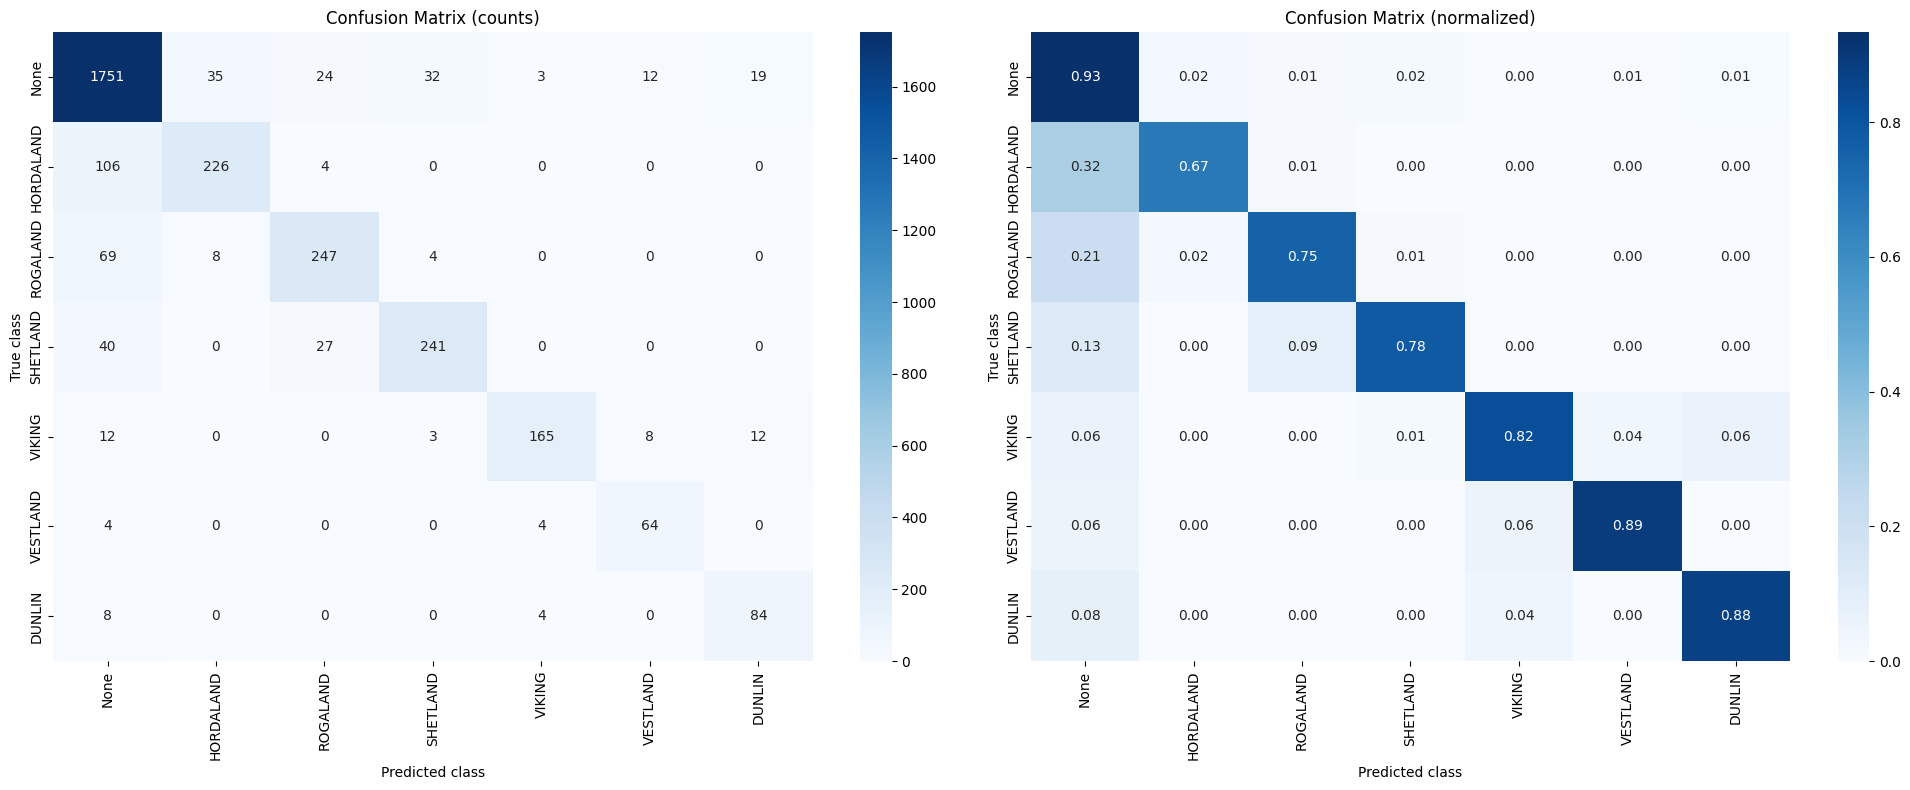

Per-class accuracy:
  None           : 0.933
  HORDALAND      : 0.673
  ROGALAND       : 0.753
  SHETLAND       : 0.782
  VIKING         : 0.825
  VESTLAND       : 0.889
  DUNLIN         : 0.875
  OVERALL        : 0.864


In [11]:
# confusion matrix on the validation set, needs the best-model cell above

def show_confusion_matrix_heatmap(learn, dls, pred_labels, title="Confusion Matrix", figsize=(10, 8)):
    """Display a confusion matrix as a seaborn heatmap with per-class accuracy."""
    val_preds, val_targs = learn.get_preds(dl=dls.valid)
    val_pred_classes = val_preds.argmax(dim=1).numpy()
    val_true_classes = val_targs.numpy()

    cm = confusion_matrix(val_true_classes, val_pred_classes, labels=list(range(len(pred_labels))))
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

    fig, axes = plt.subplots(1, 2, figsize=(figsize[0] * 2, figsize[1]))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=pred_labels, yticklabels=pred_labels, ax=axes[0])
    axes[0].set_title(f"{title} (counts)")
    axes[0].set_ylabel("True class")
    axes[0].set_xlabel("Predicted class")

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=pred_labels, yticklabels=pred_labels, ax=axes[1])
    axes[1].set_title(f"{title} (normalized)")
    axes[1].set_ylabel("True class")
    axes[1].set_xlabel("Predicted class")

    plt.tight_layout()
    plt.show()

    per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    print("Per-class accuracy:")
    for lbl, acc_val in zip(pred_labels, per_class_acc):
        print(f"  {lbl:15s}: {acc_val:.3f}")
    print(f"  {'OVERALL':15s}: {cm.diagonal().sum() / cm.sum():.3f}")

if 'learn_best' in dir():
    show_confusion_matrix_heatmap(learn_best, dls_best, pred_column_best)
else:
    print("Run the best-model cell above first (learn_best not defined).")